# Linear Regression

**Objective:** Learn linear regression with simple, step-by-step examples.

## What is regression?

**Regression** is a supervised learning task where the target is a number, such as price, temperature or exam score. Supervised means the training examples include the correct target values. Linear regression assumes that a weighted straight-line relationship is a useful approximation of how inputs relate to the numeric target.

## How It Works
Linear regression learns a straight-line relationship between input features and a numeric target.

## Intuition: fit the best straight line

Imagine plotting house area on the horizontal axis and house price on the vertical axis. A line summarizes the overall trend. The model chooses a slope and intercept so that the line's predictions are close to the observed training values. The line will not pass through every point because real data contains variation and noise.

## 1. Import Libraries
We start with the standard tools used in many scikit-learn examples.

### Libraries and reproducibility

Pandas loads tabular data, Matplotlib draws the diagnostic scatter plot, and `train_test_split` reserves examples for evaluation. `RANDOM_STATE` makes the random split repeatable.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

## 2. Load the Dataset
The CSV file is stored inside this topic folder so the notebook is self-contained.

### Understand the dataset

The CSV has four input measurements (`bmi`, `blood_pressure`, `age`, `glucose`) and one numeric `target`. `head()` previews rows. `shape` reports rows and columns; `info()` reports data types and missing values; `describe()` summarizes numeric columns. This is a small educational dataset, not a clinical tool.

In [2]:
data = pd.read_csv('datasets/diabetes.csv')
data.head()

,bmi,blood_pressure,age,glucose,target
0,29.52,72.35,58.6,120.35,272.52
1,22.80,74.75,47.9,149.40,348.75
2,31.75,103.28,62.9,117.20,391.51
3,32.70,73.79,58.3,128.94,332.15
4,18.24,90.38,70.0,113.64,295.50


## 3. Explore the Data
Always inspect shape, columns, missing values, and basic statistics before modeling.

### Inspect data quality before training

The shape tells us how many examples and columns are present. `info()` prints column types and non-null counts. `describe()` helps reveal scales and ranges. These checks help catch missing values, incorrect types and surprising magnitudes before fitting a model.

In [3]:
print(data.shape)
print(data.info())
data.describe()

(160, 5)
<class 'pandas.DataFrame'>
RangeIndex: 160 entries, 0 to 159
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   bmi             160 non-null    float64
 1   blood_pressure  160 non-null    float64
 2   age             160 non-null    float64
 3   glucose         160 non-null    float64
 4   target          160 non-null    float64
dtypes: float64(5)
memory usage: 6.4 KB
None


,bmi,blood_pressure,age,glucose,target
count,160.000000,160.000000,160.000000,160.000000,160.000000
mean,27.693562,82.242750,50.081875,112.780312,299.979875
std,4.322148,10.051471,11.137420,24.443934,39.783066
min,17.340000,56.330000,24.300000,43.850000,207.530000
25%,24.772500,75.037500,42.575000,96.247500,272.377500
50%,27.665000,81.550000,50.900000,112.920000,300.250000
75%,30.532500,86.945000,58.050000,128.032500,327.120000
max,42.570000,111.050000,78.600000,176.180000,395.750000


### Count missing values

`isna()` marks missing entries and `sum()` counts them column by column. Many estimators cannot fit directly when inputs contain NaN. A real workflow should decide how to impute or remove missing values using only training data.

In [4]:
data.isna().sum()

bmi               0
blood_pressure    0
age               0
glucose           0
target            0
dtype: int64

### Separate inputs and target

`X` contains the feature columns; `y` contains the target to predict. We drop `target` from X so the correct answer is not accidentally given to the model. `test_size=0.2` reserves 20% for testing. Shapes `(128, 4)` and `(32, 4)` mean 128 training rows and 32 testing rows, each with four features.

## 4. Prepare Features and Target
`X` contains the input columns. `y` contains the answer we want to predict.

In [5]:
X = data.drop(columns=['target'])
y = data['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(X_train.shape, X_test.shape)

(128, 4) (32, 4)


### Fit means learn from examples

`LinearRegression()` creates an estimator. `fit(X_train, y_train)` learns coefficients and an intercept by minimizing squared residuals. A **residual** is actual value minus predicted value. Test rows are not used in fitting.

## 5. Train the Model
The model learns patterns from the training data.

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[1.51,1.15,0.87,1.2 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['bmi','blood_pressure','age','glucose']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-13.54
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,4


### Predict and evaluate

`predict` applies the learned relationship to held-out rows. MAE is average absolute error in target units. RMSE is the square root of average squared error and penalizes large errors more strongly. R-squared compares the model with a constant-mean baseline; it can be negative on test data if the model is worse than that baseline.

## 6. Predict and Evaluate
For regression, common metrics are MAE, RMSE, and R-squared.

In [7]:
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = (mean_squared_error(y_test, predictions) ** 0.5)
r2 = r2_score(y_test, predictions)

print('MAE:', round(mae, 2))
print('RMSE:', round(rmse, 2))
print('R2:', round(r2, 2))

MAE: 23.9
RMSE: 28.96
R2: 0.53


### Read the actual-vs-predicted plot

Each point compares a real target with the model's prediction. Points close to the ideal diagonal indicate smaller errors. A curve or widening spread can indicate model misspecification or unequal error variance. The plot is a diagnostic, not a replacement for metrics.

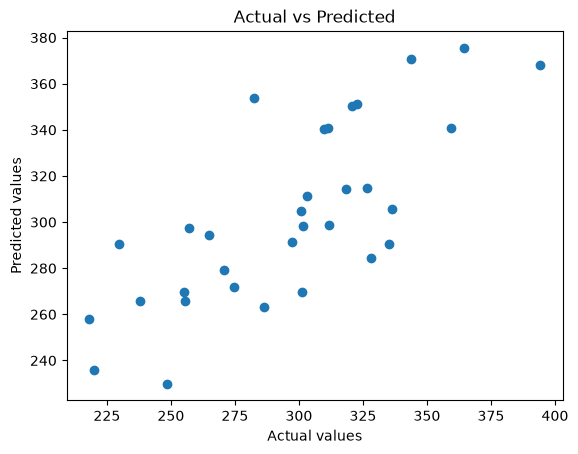

In [8]:
plt.scatter(y_test, predictions)
plt.xlabel('Actual values')
plt.ylabel('Predicted values')
plt.title('Actual vs Predicted')
plt.show()

## Linear regression mathematics

For one feature, `y_hat = b0 + b1*x`, where `b0` is the intercept and `b1` is the slope. For multiple features: `y_hat = b0 + b1*x1 + ... + bp*xp`. Ordinary least squares chooses coefficients to minimize `sum((y_i - y_hat_i)^2)`. Squaring residuals makes large errors count more and gives a differentiable objective.

## Assumptions and limitations

Common assumptions include a reasonably linear relationship in the parameters, independent errors, constant error variance (homoscedasticity), and no perfect multicollinearity. Normal residuals matter mainly for some small-sample statistical inference, not as a strict requirement for producing predictions. Outliers can strongly affect least-squares fitting.

## Key terms

- **Supervised learning:** examples include known targets.
- **Coefficient:** expected prediction change for a one-unit feature change, holding other features fixed.
- **Intercept:** predicted target when all feature values are zero.
- **Residual:** actual minus predicted value.
- **Least squares:** fitting by minimizing squared residuals.
- **MAE / RMSE:** error metrics measured in target units.

## Check your understanding

1. Why must `target` be removed from X?
2. Why do we keep a test set separate from training?
3. Which metric penalizes large errors more strongly: MAE or RMSE?
4. Does a high R-squared prove a model is causal or safe to use?

## Try This Yourself
- Change `test_size` from `0.2` to `0.3`.
- Print the first 10 predictions.
- Add or remove one feature and compare the metrics.